In [27]:
#a model assigns an input to one of three or more mutually exclusive classes.
#For example, suppose we give a model an image of a handwritten digit.
#It must decide whether the image represents 0, 1, 2, 3, and so on up to 9.
#The model must choose one of 10 possible classes, so this is multiclass classification.

In [28]:
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [29]:
print("Tensorflow Version: ", tf.__version__)
print("Keras Version: ", tf.keras.__version__)

Tensorflow Version:  2.21.0
Keras Version:  3.13.2


In [30]:
(X_train, y_train) , (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [31]:
print(
    "No. of training examples:", X_train.shape[0],
    "and each image is of shape (%d, %d), i.e., pixels"
    % (X_train.shape[1], X_train.shape[2])
)

No. of training examples: 60000 and each image is of shape (28, 28), i.e., pixels


In [32]:
print(
    "Number of test examples:", X_test.shape[0],
    "and each image is of shape (%d, %d), i.e. pixels"
    % (X_test.shape[1], X_test.shape[2])
)

Number of test examples: 10000 and each image is of shape (28, 28), i.e. pixels


In [33]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

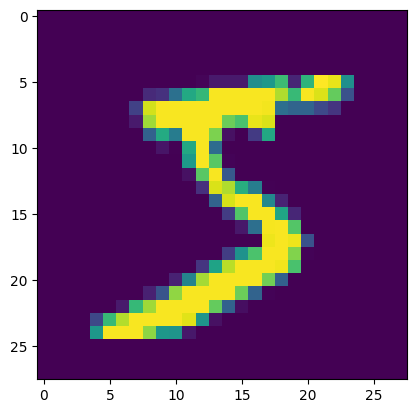

In [34]:
plt.imshow(X_train[0])

In [35]:
y_train[0]

np.uint8(5)

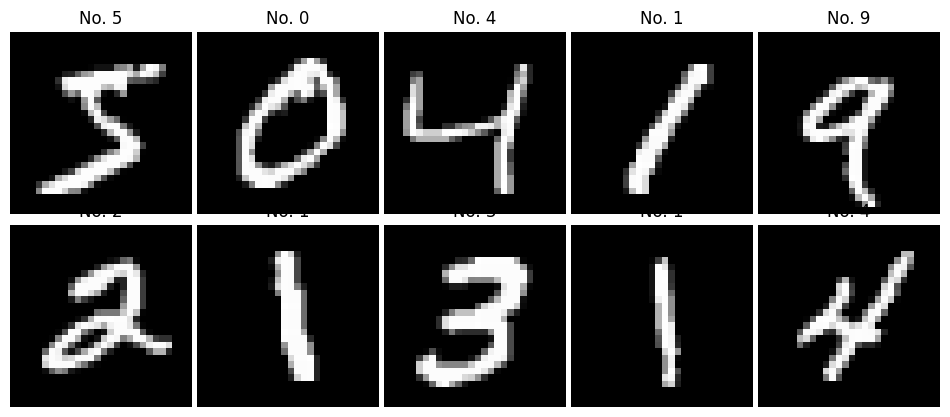

<Figure size 640x480 with 0 Axes>

In [36]:
num_rows, num_cols = 2,5
f, ax = plt.subplots(num_rows, num_cols, figsize=(12,5),
                     gridspec_kw={'wspace':0.03, 'hspace':0.01},
                     squeeze=True)

for r in range(num_rows):
    for c in range(num_cols):
        image_index = r * 5 + c
        ax[r,c].axis("off")
        ax[r,c].imshow(X_train[image_index], cmap='gray')
        ax[r,c].set_title('No. %d' % y_train[image_index])
plt.show()
plt.tight_layout()

In [37]:
X_train.shape

(60000, 28, 28)

In [38]:
# Flatten the data to 2D

# Converting each 28x28 image into a 1D vector of 784 pixels
X_train = X_train.reshape(X_train.shape[0],X_train.shape[1] * X_train.shape[2])

X_test = X_test.reshape(X_test.shape[0],X_test.shape[1] * X_test.shape[2])

# Checking the shapes after flattening
print("Number of training examples:", X_train.shape[0],"and each image is of shape (%d)" % X_train.shape[1])

print("Number of test examples:", X_test.shape[0], "and each image is of shape (%d)" % X_test.shape[1])

Number of training examples: 60000 and each image is of shape (784)
Number of test examples: 10000 and each image is of shape (784)


In [39]:
#normalizing the data

# x = (X - Xmin)/ (Xmax - Xmin) = X / 255

In [40]:
X_train = X_train/255
X_test = X_test/255

In [41]:
print(X_train[0])

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         

In [42]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [43]:
# model-architecture

#2 key architecture decisions to be made about such a stack of dense layer-:
# 1. how many layers to use
# 2. how many hidden units to choose for each layer

# output layer -> softmax activation function -> probabilities

In [44]:
#creating a neural network

In [45]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation

In [46]:
# Define input and output dimensions
input_dims = X_train.shape[1]
output_dims = 10

# Create the Sequential model
model = Sequential()

# First hidden layer
model.add(
    Dense(
        512,
        input_shape=(input_dims,),
        activation="relu",
        name="HiddenLayer1"
    )
)

# Second hidden layer
model.add(
    Dense(
        128,
        activation="relu",
        name="HiddenLayer2"
    )
)

# Output layer for 10 digit classes
model.add(
    Dense(
        output_dims,
        activation="softmax",
        name="OutputLayer"
    )
)

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ HiddenLayer1 (Dense)            │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ HiddenLayer2 (Dense)            │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ OutputLayer (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,874 (1.79 MB)

 Trainable params: 468,874 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

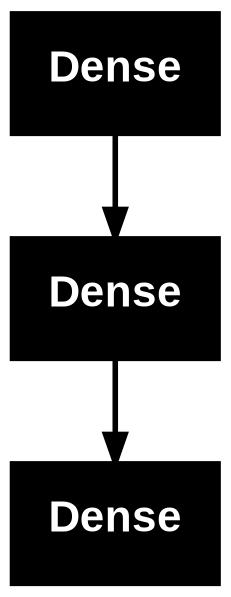

In [47]:
from tensorflow.keras.utils import plot_model
plot_model(model)

In [50]:
from tensorflow.keras.optimizers import RMSprop
optimizer = RMSprop(0.001) #here, we have set our learning rate as 0.001
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [51]:
#training a NN
batch_size = 128
num_epochs = 20
multiclass_classifier = model.fit(X_train, y_train, validation_split = 0.2, epochs = num_epochs, batch_size = batch_size, verbose = 1)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9221 - loss: 0.2670 - val_accuracy: 0.9613 - val_loss: 0.1295
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9711 - loss: 0.0975 - val_accuracy: 0.9695 - val_loss: 0.1001
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9806 - loss: 0.0618 - val_accuracy: 0.9757 - val_loss: 0.0828
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9871 - loss: 0.0410 - val_accuracy: 0.9770 - val_loss: 0.0789
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9904 - loss: 0.0312 - val_accuracy: 0.9752 - val_loss: 0.0826
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9927 - loss: 0.0231 - val_accuracy: 0.9777 - val_loss: 0.0799
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9939 - loss: 0.0188 - val_accuracy: 0.9778 - val_loss: 0.0826
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9955 - loss: 0.0145 - val_accu

In [52]:
score = model.evaluate(x=X_test, y=y_test, verbose=0)
print('Test score:', score[0])
print('Test accuracy:', score[1])

Test score: 0.11235865205526352
Test accuracy: 0.9797999858856201


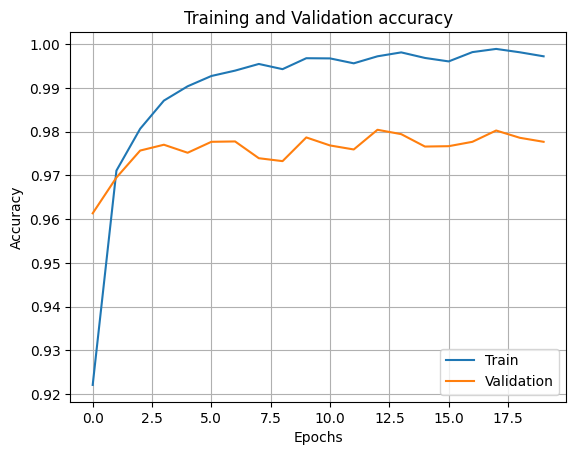

In [53]:
plt.plot(multiclass_classifier.history['accuracy'])
plt.plot(multiclass_classifier.history['val_accuracy'])
plt.title('Training and Validation accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['Train', 'Validation'])
plt.grid()
plt.show()

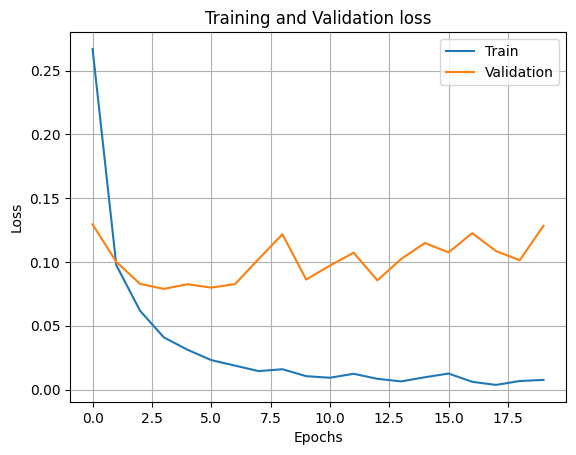

In [54]:
plt.plot(multiclass_classifier.history['loss'])
plt.plot(multiclass_classifier.history['val_loss'])
plt.title('Training and Validation loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['Train', 'Validation'])
plt.grid()
plt.show()

In [56]:
y_test[0:10]

array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9], dtype=uint8)

In [57]:
#prediction on test dataset using predict() func
y_pred = model.predict(X_test)
y_pred[:10]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


array([[5.62335274e-16, 1.64107213e-15, 7.57973150e-16, 1.90730508e-14,
        6.33224126e-21, 3.71940108e-18, 5.43473495e-21, 9.99999940e-01,
        1.12263981e-18, 1.01270961e-13],
       [3.90144445e-23, 2.09529031e-16, 9.99999940e-01, 3.54126885e-21,
        5.03845326e-31, 9.85287348e-27, 2.08385817e-25, 3.22881431e-23,
        1.27017965e-23, 2.40874177e-30],
       [7.00761893e-10, 9.99996841e-01, 2.22281557e-07, 5.58559414e-11,
        1.28782637e-10, 3.25359473e-08, 2.90821389e-09, 1.70414637e-06,
        1.21403696e-06, 1.33621308e-11],
       [9.99999940e-01, 2.99960816e-12, 1.14346532e-08, 5.66807987e-14,
        1.17161359e-12, 1.63380056e-16, 3.67995812e-09, 8.24149234e-13,
        1.55196990e-16, 1.71743464e-09],
       [1.37886312e-13, 1.17920825e-17, 2.52586851e-13, 4.44753426e-18,
        9.99999821e-01, 1.88994240e-16, 6.34845768e-17, 1.07600335e-11,
        5.88596885e-15, 1.71519218e-07],
       [1.95959332e-10, 9.99976337e-01, 2.71276029e-10, 1.44886121e-12,
   

In [58]:
y_pred = np.array([np.argmax(pred) for pred in y_pred])

In [59]:
y_pred[: 10], y_test[0:10]

(array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9]),
 array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9], dtype=uint8))

In [60]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

In [61]:
# This function plots the confusion matrices given y_i, y_i_hat.
def plot_confusion_matrix(y_test, y_predict):
    cm = confusion_matrix(y_test, y_predict)
    labels = list(np.unique(y_test))

    # Color Map
    cmap = sns.light_palette("blue")

    # Plot Confusion Matrix
    plt.figure(figsize=(12, 12))
    sns.heatmap(cm, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Values')
    plt.ylabel('Actual Values')
    plt.title("Confusion matrix")
    plt.show()

    print()
    print('-'*100)
    print("Classification Report:\n", classification_report(y_test, y_predict))
    print('Accuracy Score: ' + str(accuracy_score(y_test, y_predict)*100))

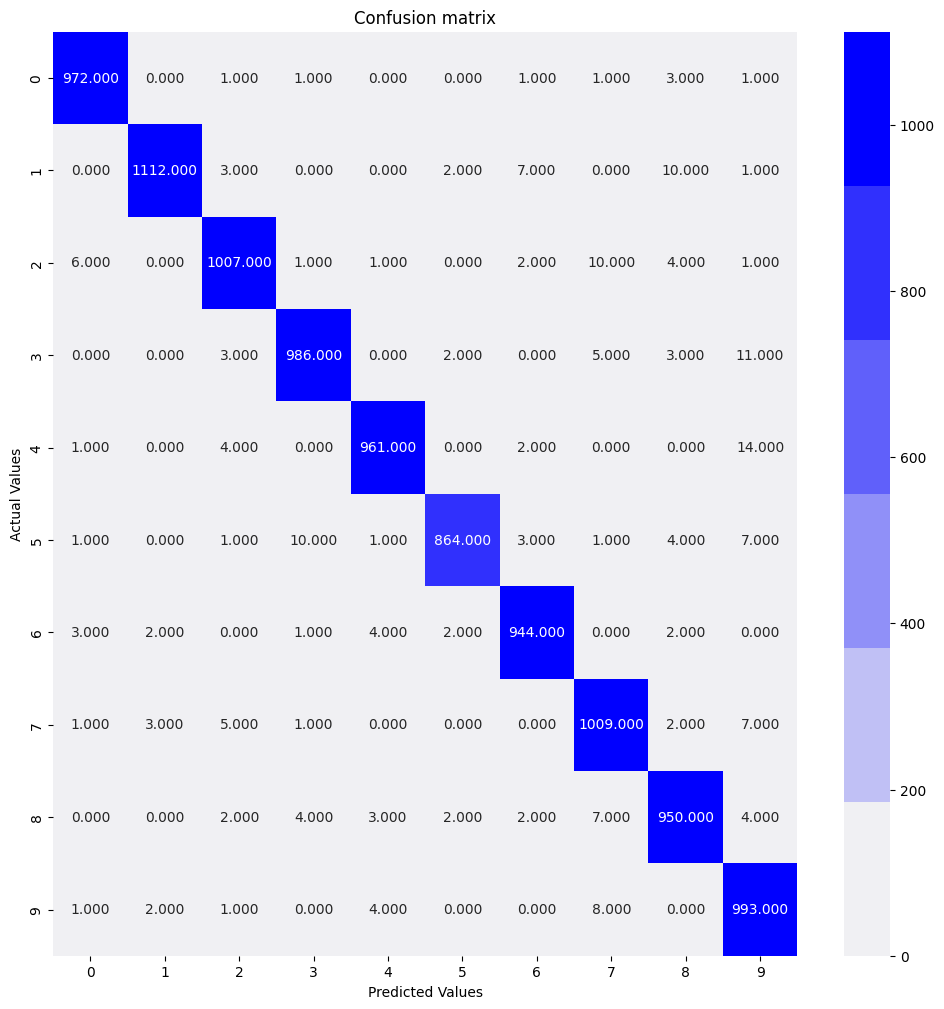


----------------------------------------------------------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.98      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.99      0.98      0.98       982
           5       0.99      0.97      0.98       892
           6       0.98      0.99      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.97      0.98      0.97       974
           9       0.96      0.98      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

Accuracy Score: 97.98


In [62]:
plot_confusion_matrix(y_test, y_pred)